# Example of the aitlas toolbox in the context of image segmentation

This notebook shows a sample implementation of semantic segmentation using the aitlas toolbox. The DynamicEarthNet dataset contains time series images of Sentinel-1, Sentinel-2 and PlanetScope. S1 and S2 time series are monthly, while Planet is daily. Note: each S1 and S2 image is associated to a label mask, but only the first PlanetScope image of each month is associated to a mask.

## Import the required packages

In [ ]:
from aitlas.datasets import DynamicEarthNetDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor
import matplotlib.pyplot as plt

## Visualize images and masks

All image sources

Total number of patches: 1270


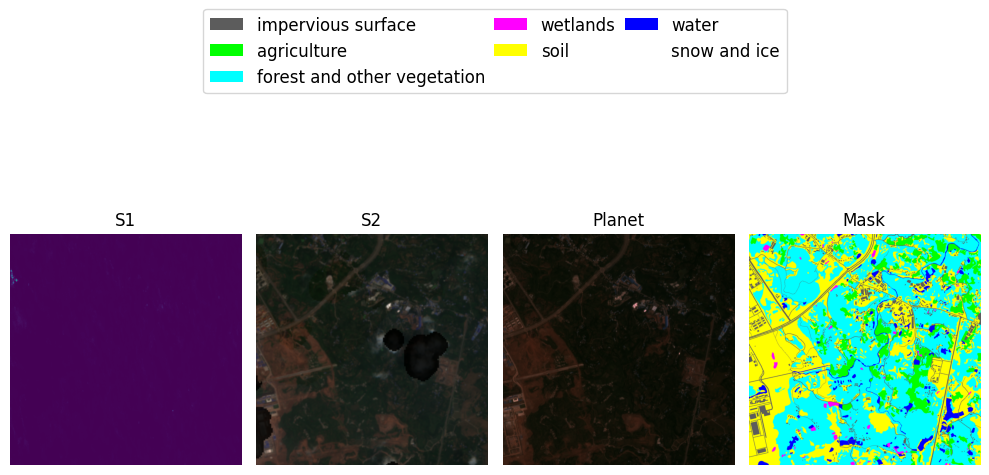

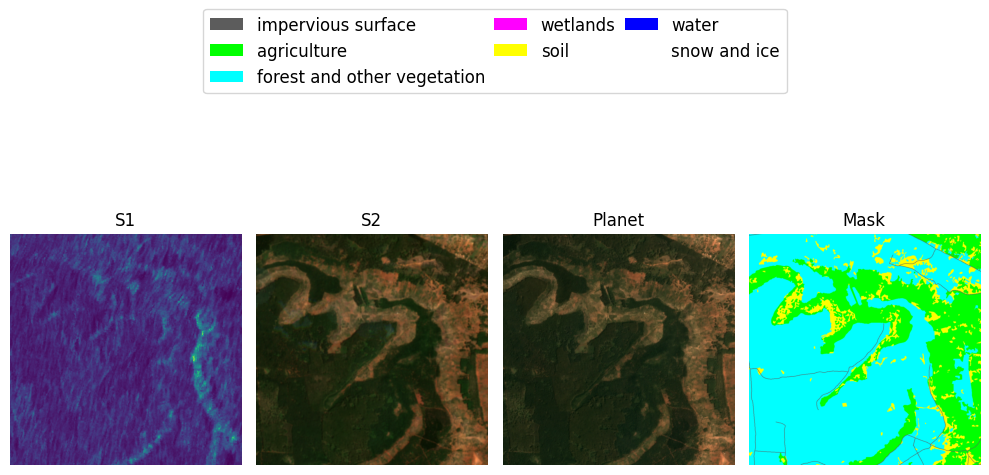

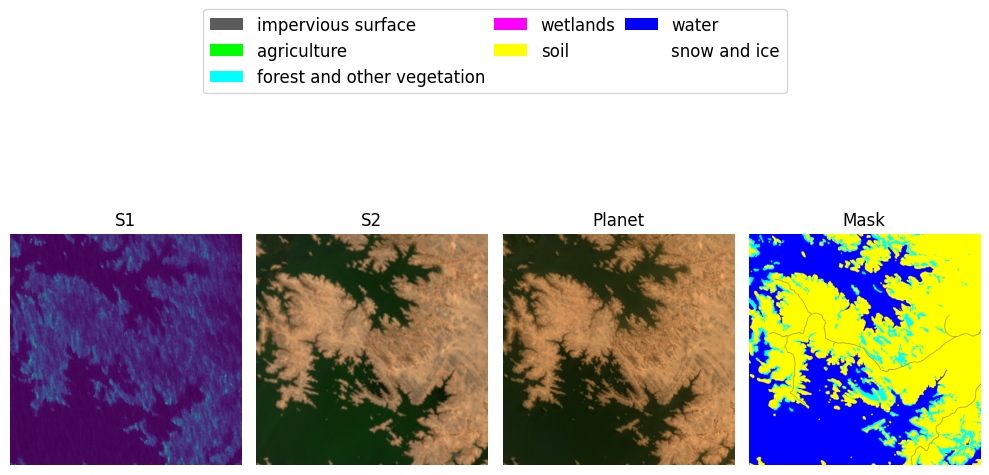

In [ ]:
dataset_config = {
    "data_dir": "./data/dynamicearthnet",
    "imagery": "all",
    "selection": "rgb",
    "timeseries": False
}
dataset = DynamicEarthNetDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(10);
dataset.show_image(100);
dataset.show_image(200);

Sentinel-2 images

Total number of patches: 1320


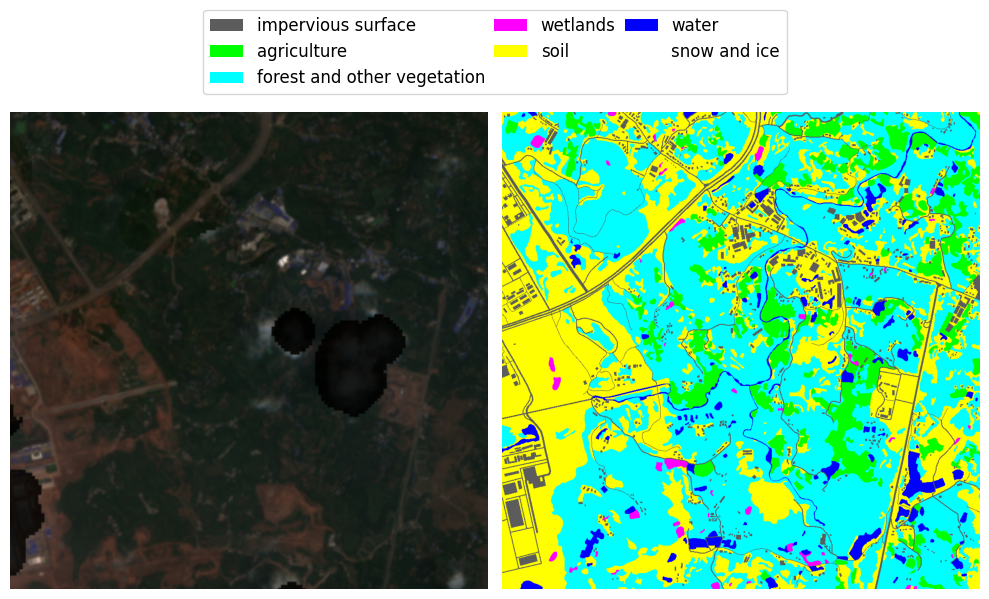

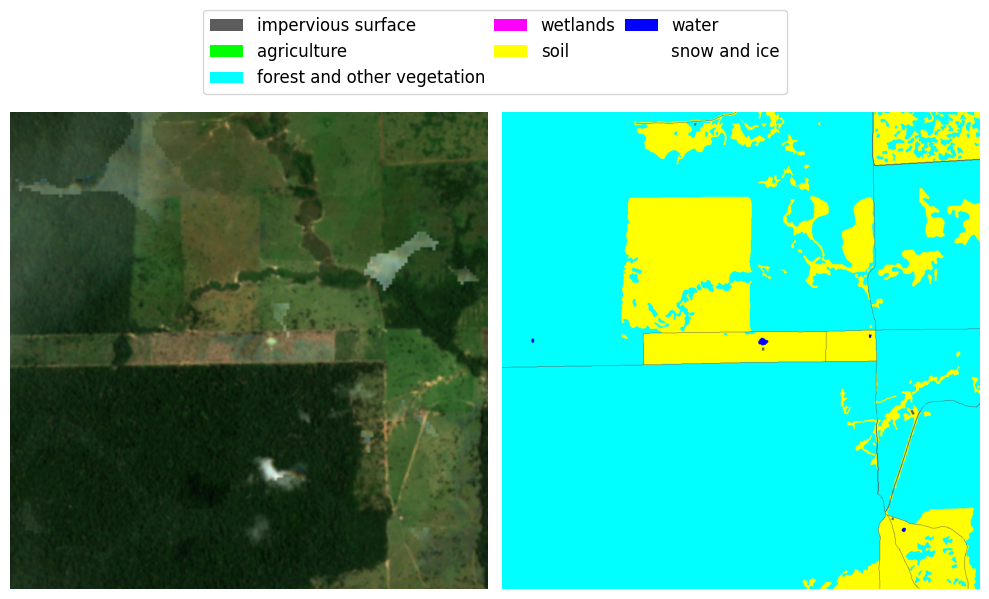

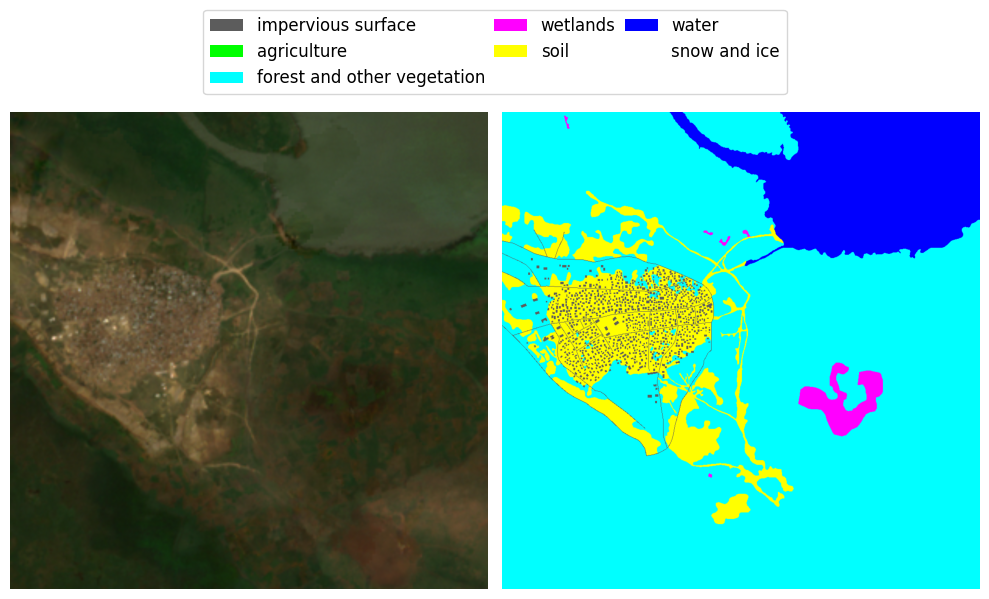

In [ ]:
dataset_config = {
    "data_dir": "./data/dynamicearthnet",
    "imagery": "s2",
    "selection": "rgb",
    "timeseries": False
}
dataset = DynamicEarthNetDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(10);
dataset.show_image(100);
dataset.show_image(200);

Sentinel-1

Total number of patches: 1270


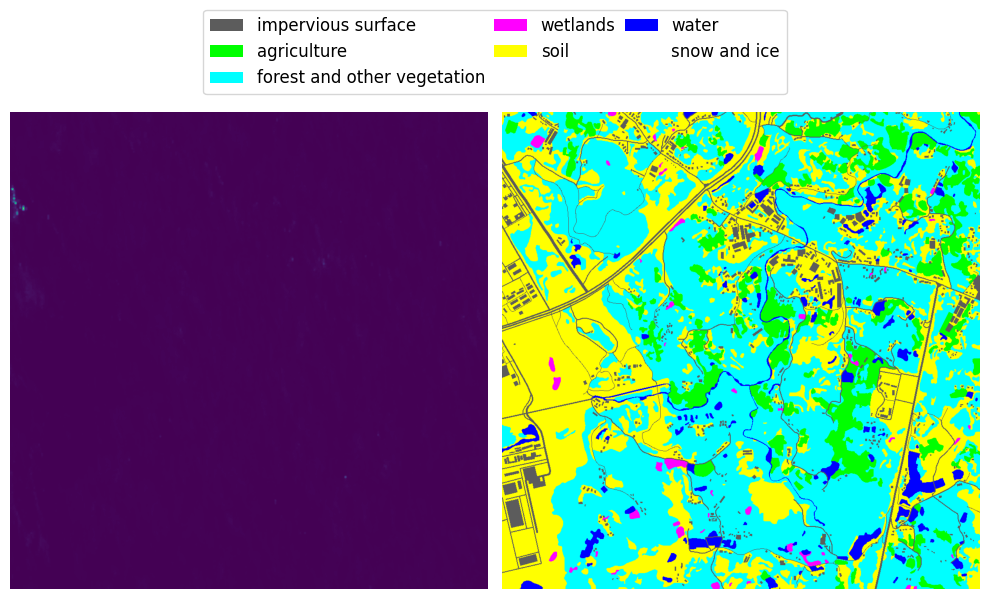

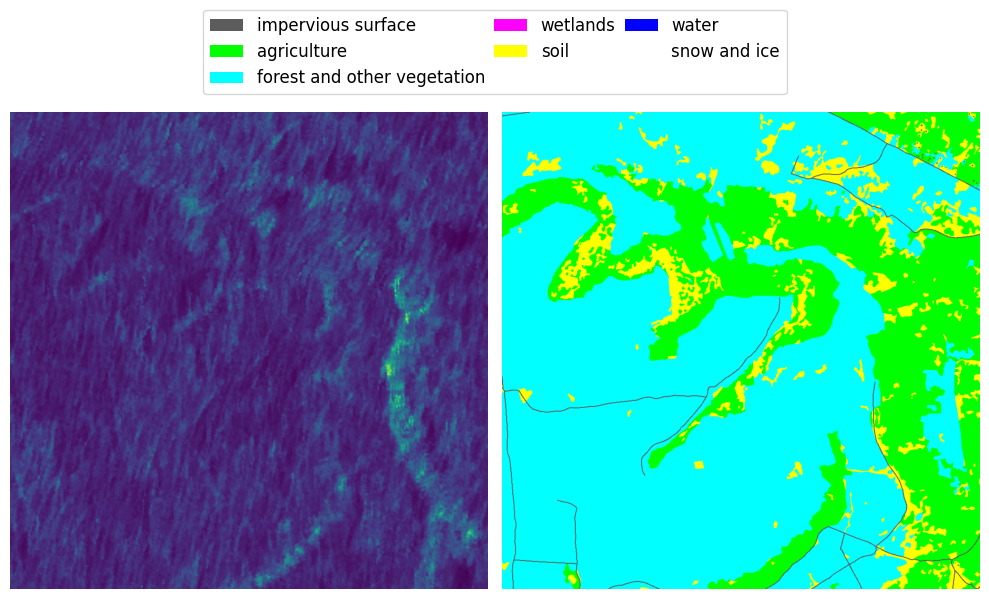

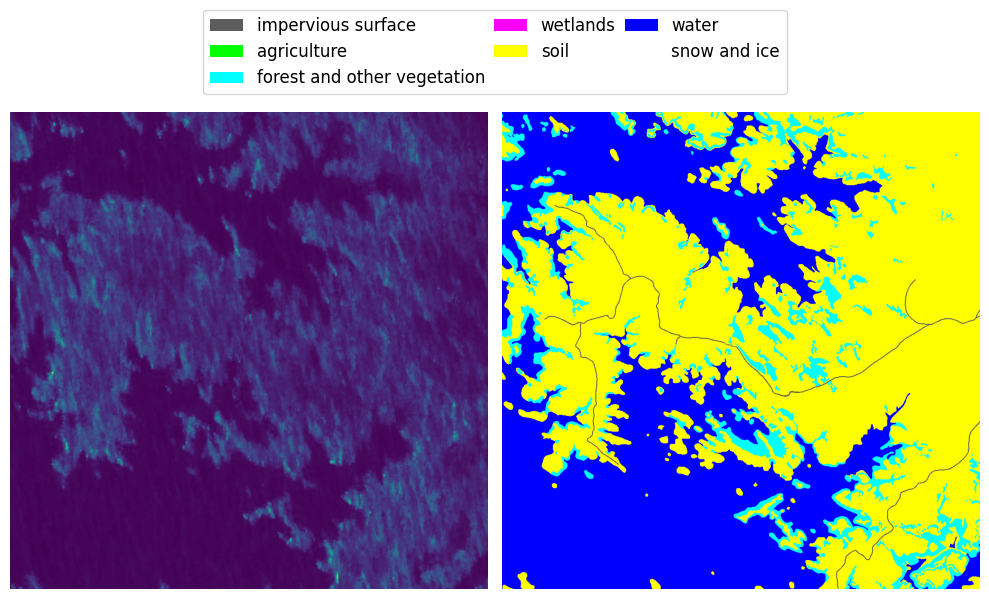

In [ ]:
dataset_config = {
    "data_dir": "./data/dynamicearthnet",
    "imagery": "s1",
    "selection": "rgb",
    "timeseries": False
}
dataset = DynamicEarthNetDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(10);
dataset.show_image(100);
dataset.show_image(200);

Planet images

Total number of patches: 1320


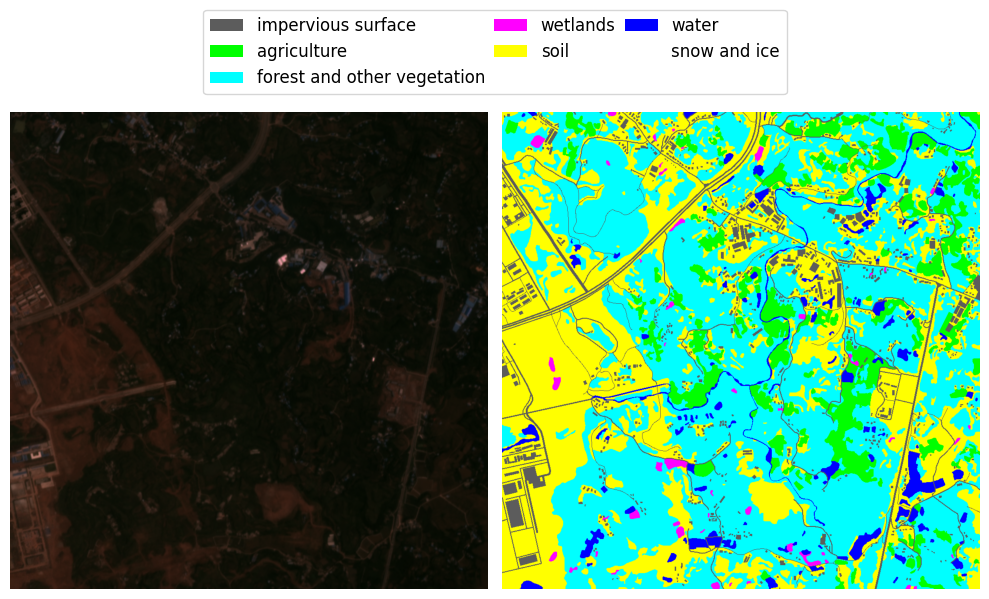

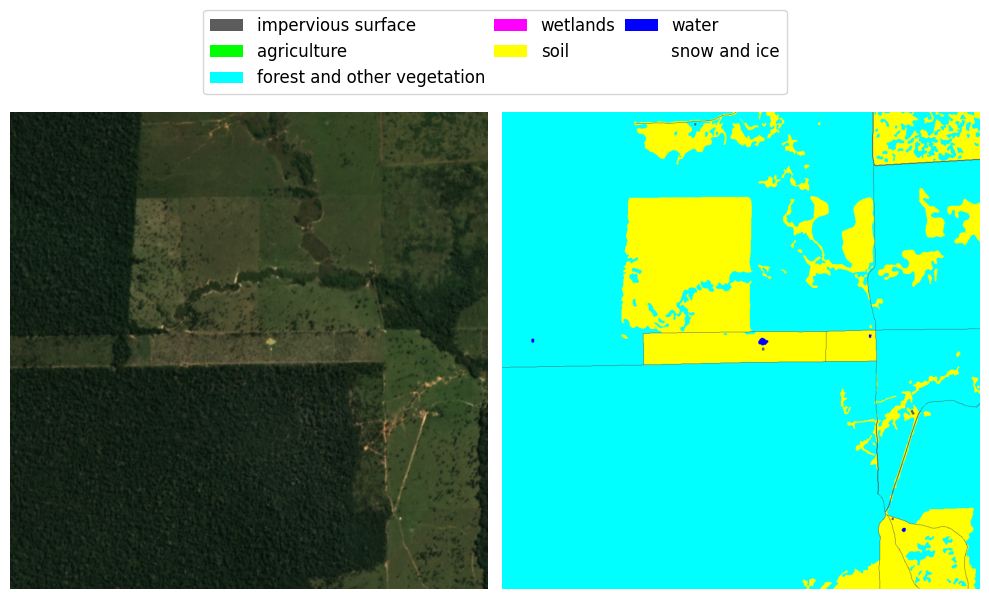

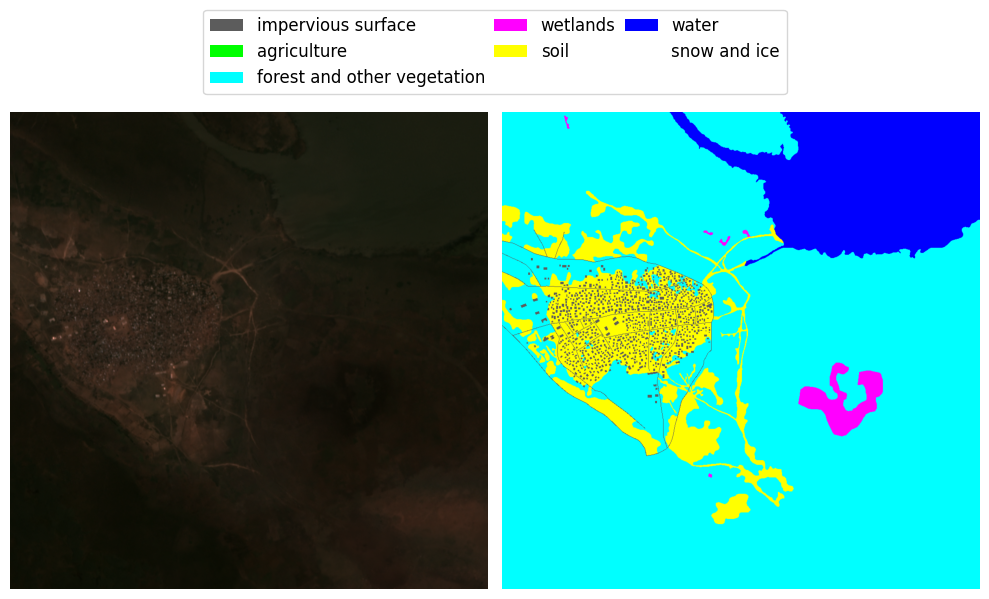

In [ ]:
dataset_config = {
    "data_dir": "./data/dynamicearthnet",
    "imagery": "planet",
    "selection": "rgb",
    "timeseries": False
}
dataset = DynamicEarthNetDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(10);
dataset.show_image(100);
dataset.show_image(200);

In [71]:
dataset.data_distribution_table()

,Number of pixels
impervious surface,95203018.0
agriculture,154695930.0
forest and other vegetation,617596017.0
wetlands,4775128.0
soil,390358378.0
water,106204971.0
snow and ice,18705849.0


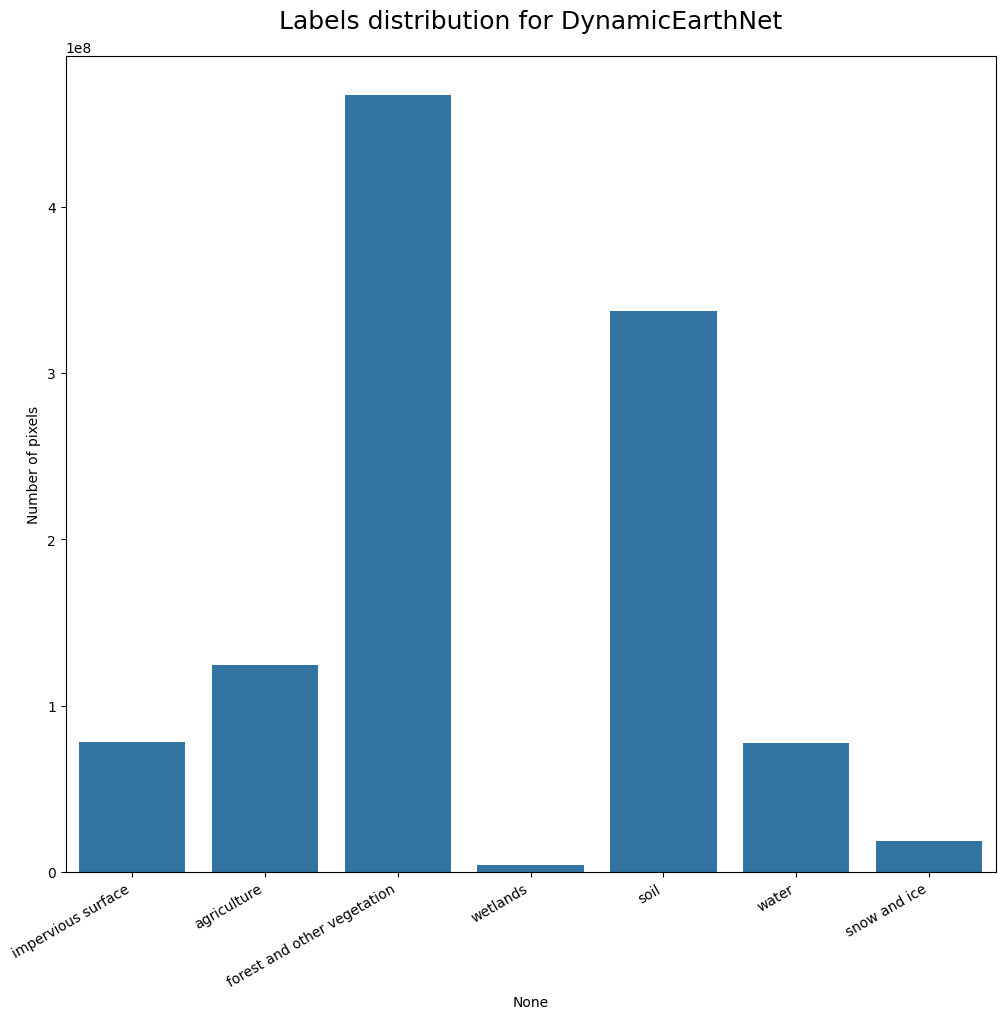

In [55]:
dataset.data_distribution_barchart();

## Time series plot ##

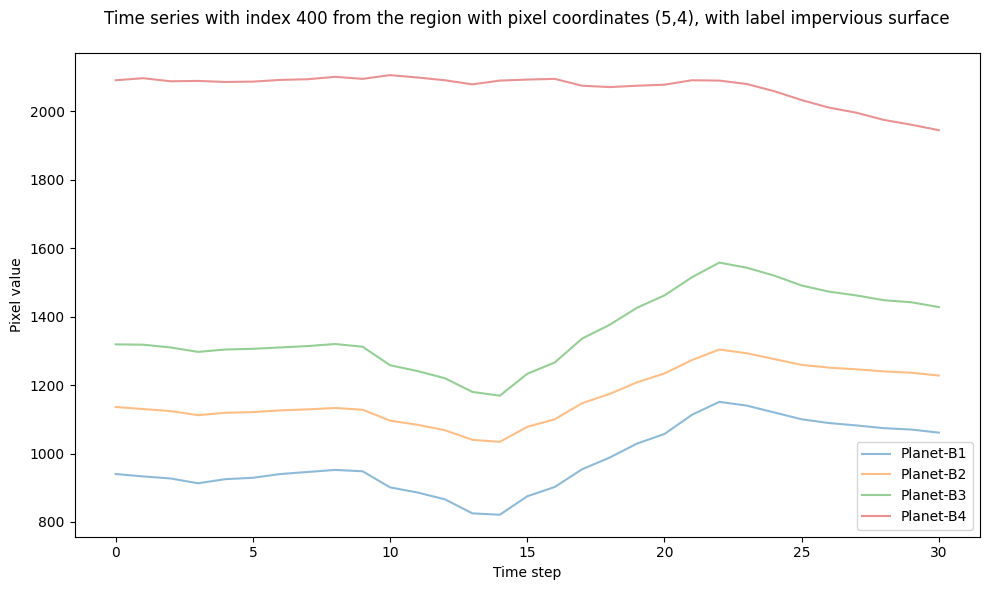

In [ ]:
dataset_config = {
    "data_dir": "./data/dynamicearthnet",
    "imagery": "planet",
    "timeseries": True
}
dataset = DynamicEarthNetDataset(dataset_config) 

fig = dataset.show_timeseries(index=400, longitude=5, latitude=4)

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 4,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/dynamicearthnet",
    "imagery": "planet",
    "selection": "rgb",
    "timeseries": False,
    "mode": "train",    
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = DynamicEarthNetDataset(train_dataset_config)
len(train_dataset)

792

## Create the model

In [ ]:
epochs = 30
model_directory = "./data/experiments/dynamicearthnet"
model_config = {
    "num_classes": 7, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [125]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2026-05-28 11:26:13,087 INFO Starting training.
training: 100%|██████████| 198/198 [00:19<00:00, 10.29it/s]
2026-05-28 11:26:32,402 INFO epoch: 1, time: 19, loss:  0.70372
testing on train set: 100%|██████████| 198/198 [00:19<00:00, 10.07it/s]
2026-05-28 11:26:54,608 INFO IOU:0.12286554800729783, IOU mean:0.10720915267745688, IOU per Class:[0.         0.11277675 0.15378218 0.         0.17710984 0.06368441
 0.24311088]
training: 100%|██████████| 198/198 [00:20<00:00,  9.89it/s]
2026-05-28 11:27:14,635 INFO epoch: 2, time: 20, loss:  0.61364
testing on train set: 100%|██████████| 198/198 [00:20<00:00,  9.70it/s]
2026-05-28 11:27:35,069 INFO IOU:0.20771418350275295, IOU mean:0.12513574460705007, IOU per Class:[0.         0.11626534 0.32549085 0.         0.1770731  0.
 0.25712092]
training: 100%|██████████| 198/198 [00:20<00:00,  9.80it/s]
2026-05-28 11:27:55,278 INFO epoch: 3, time: 20, loss:  0.56798
testing on train set: 100%|██████████| 198/198 [00:19<00:00, 10.13it/s]
2026-05-28 11:28

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/dynamicearthnet",
    "imagery": "planet",
    "selection": "rgb",
    "timeseries": False,
    "mode": "val",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = DynamicEarthNetDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/experiments/dynamicearthnet/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

264


2026-05-28 11:54:17,002 INFO Loading checkpoint /home/dragik/data/FAIR_EO/dynamicearthnet/checkpoint.pth.tar
2026-05-28 11:54:17,563 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/dynamicearthnet/checkpoint.pth.tar at epoch 31
testing on test set: 100%|██████████| 66/66 [00:07<00:00,  8.30it/s]


[{'IOU': 0.26310926518343963,
  'IOU mean': 0.07986970077868416,
  'IOU per Class': array([0.        , 0.00560665, 0.46507281, 0.        , 0.08840845,
         0.        , 0.        ])}]

## Predictions

2026-05-28 11:54:55,448 INFO Loading checkpoint /home/dragik/data/FAIR_EO/dynamicearthnet/checkpoint.pth.tar
2026-05-28 11:54:55,950 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/dynamicearthnet/checkpoint.pth.tar at epoch 31


264


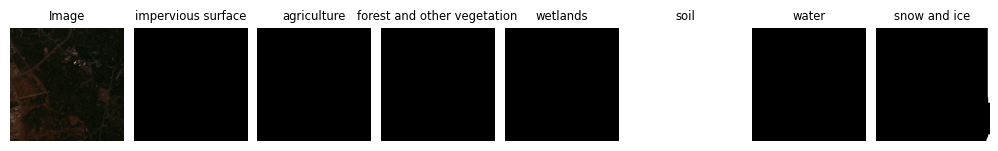

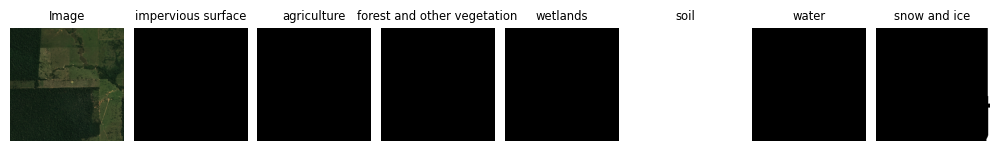

In [ ]:
model_path = "./data/experiments/dynamicearthnet/checkpoint.pth.tar"
labels = ["impervious surface","agriculture","forest and other vegetation","wetlands","soil","water","snow and ice"]
transform = ResizeToTensor()
model.load_model(model_path)
plt.rcParams.update({'font.size': 7})

test_dataset_config = {
    "data_dir": "./data/dynamicearthnet",
    "imagery": "planet",
    "selection": "rgb",
    "timeseries": False,
    "mode": "test"
}
test_dataset = DynamicEarthNetDataset(test_dataset_config)
print(len(test_dataset))

image = test_dataset[0][0]
fig = model.predict_masks(image, labels, transform)

image = test_dataset[100][0]
fig = model.predict_masks(image, labels, transform)